**Linear SVM + T2: K-means Distances Appended**

This notebook trains **SVM with transformation T2** for 6 values of `C` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Linear SVM** (`LinearSVC`) also draws a straight boundary $w^\top x + b = 0$, but instead of probabilities it looks for the boundary with the widest **margin** (the biggest gap between the boundary and the closest flows of each class). Flows on the wrong side or inside the margin are penalized with the (squared) hinge loss.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \max(0,\, 1 - y_i\, w^\top x_i)^2$$

Same idea as logistic regression: **small `C` ---> strong regularization** (wide margin, tolerates more mistakes), **large `C` ---> weak regularization** (tries hard to classify every training flow correctly, risk of overfitting).

**1. Setup**

In [11]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.cluster import KMeans
from sklearn.pipeline import make_union
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The transformation: K-means distances appended (k = 20)**

K-means splits the training flows into $k$ groups so that each flow is close to its group's center, by minimizing

$$J = \sum_{i} \min_{c} \lVert x_i - \mu_c \rVert^2$$

(called **inertia**). It never sees the label. We then add each flow's distance to all 20 centers as new features:

$$x \longrightarrow \big(x,\ \lVert x - \mu_1 \rVert,\ \dots,\ \lVert x - \mu_{20} \rVert\big) \qquad 73 + 20 = 93 \text{ columns}$$

Each center is like a "typical traffic pattern" (a normal web session, a DNS lookup, a one-packet scan...), and the distance tells the SVM how much a flow looks like each pattern. Since distance is a nonlinear function of $x$, the boundary becomes curved in the original space.

**Why do we do this?**: Learned "typical patterns" from the data ---> a nonlinear basis the linear SVM can use

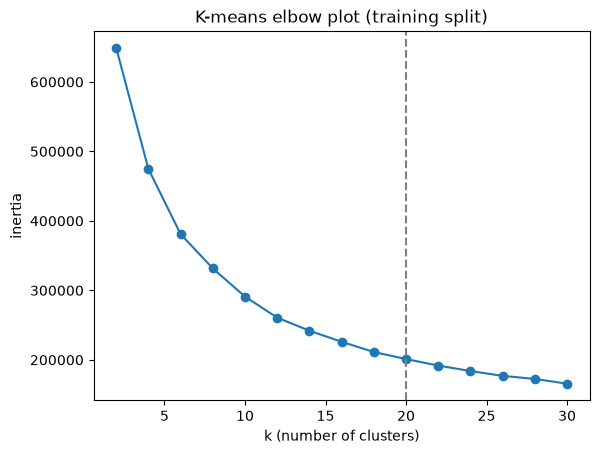

In [12]:
prep = build_preprocessor().fit(X_train)
Xt_train = prep.transform(X_train)

ks = range(2, 31, 2)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xt_train).inertia_ for k in ks]

plt.plot(list(ks), inertia, marker="o")
plt.axvline(20, color="gray", linestyle="--")
plt.xlabel("k (number of clusters)")
plt.ylabel("inertia")
plt.title("K-means elbow plot (training split)")
plt.savefig(FIGS / "svm_t2_kmeans_elbow.png", dpi=150, bbox_inches="tight")
plt.show()

Inertia always goes down as $k$ grows, so we look for the "elbow" where adding clusters stops helping much. Next, the **cluster purity** for $k = 20$: the share of attacks in each cluster and its most common attack type. If some clusters are almost all one type, attacks form natural groups even without labels.

In [13]:
km = KMeans(n_clusters=20, n_init=10, random_state=RANDOM_STATE).fit(Xt_train)
purity = (pd.DataFrame({"cluster": km.labels_, "label": y_train.values, "type": cat_train.values})
          .groupby("cluster")
          .agg(rows=("label", "size"), attack_share=("label", "mean"),
               top_type=("type", lambda s: s.mode()[0]),
               top_type_share=("type", lambda s: s.value_counts(normalize=True).iloc[0])))
purity.sort_values("rows", ascending=False).round(3)

,rows,attack_share,top_type,top_type_share
cluster,,,,
0,2833,0.000,Normal,1.000
11,2546,0.743,Fuzzers,0.405
4,2505,0.032,Normal,0.968
1,1940,0.944,Exploits,0.527
16,1716,0.514,Normal,0.486
10,1626,0.886,Fuzzers,0.325
3,1568,0.848,Fuzzers,0.217
12,1517,0.883,Exploits,0.666
17,1269,0.002,Normal,0.998


The elbow plot doesn't have one sharp elbow. Inertia drops fast from k = 2 to about k = 10 (from around 650,000 to 290,000), and after that it keeps going down slowly. So k = 20 is past the point where adding clusters helps a lot, but it still lowers inertia to about 200,000, and since each cluster only adds one distance column, the cost of using 20 instead of 10 is small. We kept k = 20 to get a finer set of "typical patterns".

The purity table is the interesting part. Even though K-means never saw the labels, a lot of the clusters are almost pure:
- **Normal traffic groups together really well.** 7 clusters are less than 5% attack (clusters 0, 4, 17, 9, 2, 5, 13), and together they hold roughly 70% of all the normal flows in the training set.
- **Generic gets its own cluster.** Cluster 8 is 99.9% attack, and 92.6% of it is Generic, which makes sense since Generic attacks are very repetitive.
- **The other attack types mix together.** Exploits is the most common type in four clusters, but never more than 67% of one. So K-means can tell attacks apart from normal traffic, but mostly not one attack type from another.
- **The mixed clusters are where Fuzzers live.** Clusters 16, 6, 18, 7 and 11 are between 47% and 74% attack, and Fuzzers are the top attack type in several of them (for example cluster 11, the second biggest, is 74% attack and 41% Fuzzers). This is the same Fuzzers / Normal overlap we keep seeing.

**Why does this matter?**: The distance to each center tells the SVM how close a flow is to "a normal pattern", "the Generic pattern" or "a mixed Fuzzers-like pattern" ---> that's information a straight line on the original 73 features can't express directly.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> [original features + distances to 20 K-means centers] (93 columns) ---> scaling ---> linear SVM. We scale at the end because the distances are on a different scale than the original features.

In [14]:
def build(C):
    return make_pipeline(build_preprocessor(),
                         make_union("passthrough", KMeans(n_clusters=20, n_init=10, random_state=RANDOM_STATE)),
                         StandardScaler(),
                         LinearSVC(C=C, dual="auto", max_iter=5000, random_state=RANDOM_STATE))

**4. Regularization sweep**

We train one model for each of the 6 values of `C` (smaller `C` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [15]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "SVM", "T2", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1 = 0.9113, fit time = 1.2s
C=0.01: val F1 = 0.9124, fit time = 1.16s
C=0.1: val F1 = 0.9158, fit time = 1.68s
C=1: val F1 = 0.9168, fit time = 1.72s
C=10: val F1 = 0.9166, fit time = 2.0s
C=100: val F1 = 0.9161, fit time = 2.6s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8614,0.9700,0.9125,0.1680,0.8636,0.9646,0.9113,0.1640,1.20,True,0.0012
1,0.010,0.8695,0.9654,0.9150,0.1559,0.8699,0.9592,0.9124,0.1543,1.16,True,0.0026
2,0.100,0.8778,0.9617,0.9179,0.1440,0.8788,0.9559,0.9158,0.1419,1.68,True,0.0021
3,1.000,0.8810,0.9584,0.9181,0.1393,0.8830,0.9534,0.9168,0.1360,1.72,True,0.0013
4,10.000,0.8819,0.9574,0.9181,0.1380,0.8836,0.9521,0.9166,0.1349,2.00,True,0.0015
5,100.000,0.8824,0.9574,0.9184,0.1373,0.8833,0.9514,0.9161,0.1353,2.60,True,0.0023


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

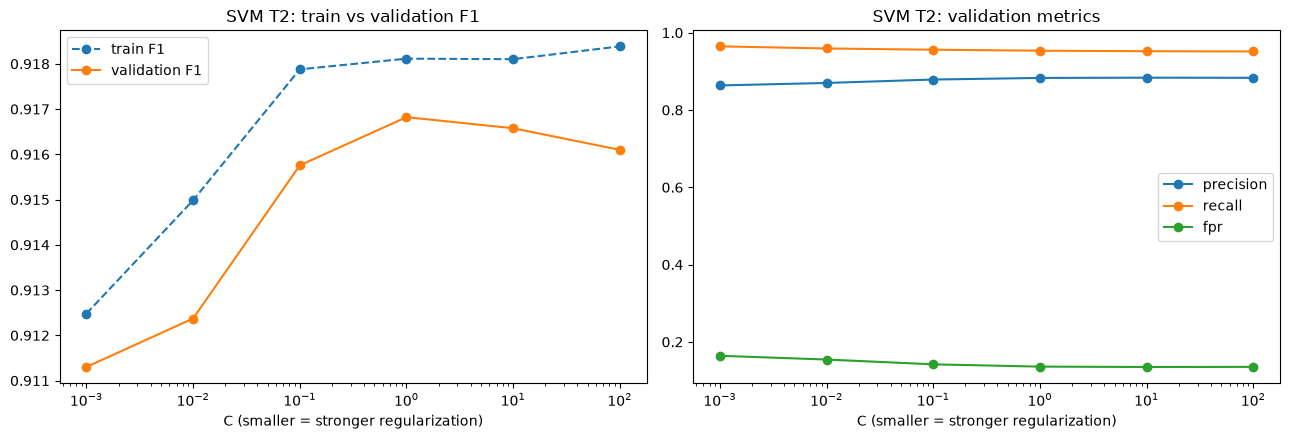

In [16]:
plot_sweep(results, "SVM T2", FIGS / "curve_svm_t2_kmeans.png")

Validation F1 goes up from 0.9113 at `C` = 0.001 to its best of 0.9170 at `C` = 1, and then stays about the same (0.9167 at `C` = 10 and 0.9161 at `C` = 100). The best `C` is in the middle of the grid, so we don't need to extend it.

There's basically no overfitting here. The train/validation gap is never bigger than 0.0026, even with the weakest regularization. Training F1 tops out around 0.918 and validation sits right below it, so the model is more limited by what a linear SVM can do with these 93 features than by the regularization. In other words, it's slightly underfitting, and lowering the regularization further doesn't help.

Like in the logistic regression models, `C` mostly shifts the balance between catching attacks and false alarms. Going from `C` = 0.001 to 100, precision goes up from 0.864 to 0.883 and FPR drops from 0.164 to 0.135, while recall goes down a little from 0.965 to 0.951. Fit time also roughly doubles (1.2s to 2.5s), but it stays fast since there are only 93 columns.

To know how much the K-means distances themselves help, we'll need to compare this with the SVM on the plain features (T0) once Victoria's results are in, since that's the same model without the distance columns.

**6. The best setting**

We pick the `C` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [17]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best C = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best C = 1: val F1 = 0.9168, precision = 0.8830, recall = 0.9534, FPR = 0.1360


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

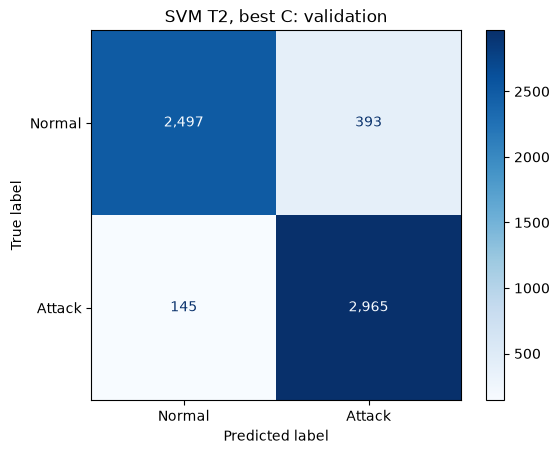

In [18]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("SVM T2, best C: validation")
plt.savefig(FIGS / "confusion_svm_t2_kmeans.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [19]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,779,120,0.867
Analysis,89,84,5,0.944
Exploits,1105,1091,14,0.987
DoS,212,210,2,0.991
Reconnaissance,419,416,3,0.993
Generic,233,232,1,0.996
Backdoor,85,85,0,1.000
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


The best model (`C` = 1) misses only 144 attacks (4.6%), the fewest of any model so far. The wide MLP missed 159 and Victoria's LR T0 missed 164. The catch is that it makes more false alarms: 393 (13.6% of normal flows), compared with 338 for the wide MLP. So this model leans towards catching attacks at the cost of flagging more normal traffic.

It's also the best model on Fuzzers so far: 120 missed (recall 86.7%), compared with 129 for LR T0 and 134 for the wide MLP. Fuzzers are still 83% of all missed attacks though, and every other type is caught at 94% or better (Backdoor, Shellcode and Worms are caught completely).

Our guess is that this comes from the clusters. Several clusters were full of Fuzzers mixed with normal flows, so the distance to those centers gives the SVM a "this looks Fuzzers-like" signal. That helps it catch more Fuzzers, but since those same clusters also contain a lot of normal traffic, it also explains why the false alarms went up. It's the same trade-off as before, just pushed a bit further towards recall.

**7. Save the results**

We save the 6 rows to `results/svm_t2_kmeans.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [20]:
results.to_csv(RESULTS / "svm_t2_kmeans.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "svm_t2_kmeans.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/svm_t2_kmeans.csv
